In [6]:
# Importing all the Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
df = pd.read_csv("C:\\Users\\sanje\\\Downloads\\fair_airline.csv")

In [8]:
df=df.drop('Unnamed: 0',axis=1)

In [9]:
df.head()

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   airline           300153 non-null  object 
 1   flight            300153 non-null  object 
 2   source_city       300153 non-null  object 
 3   departure_time    300153 non-null  object 
 4   stops             300153 non-null  object 
 5   arrival_time      300153 non-null  object 
 6   destination_city  300153 non-null  object 
 7   class             300153 non-null  object 
 8   duration          300153 non-null  float64
 9   days_left         300153 non-null  int64  
 10  price             300153 non-null  int64  
dtypes: float64(1), int64(2), object(8)
memory usage: 25.2+ MB


In [11]:
df.shape

(300153, 11)

In [12]:
df.duplicated().sum()

0

In [13]:
df.describe()

,duration,days_left,price
count,300153.000000,300153.000000,300153.000000
mean,12.221021,26.004751,20889.660523
std,7.191997,13.561004,22697.767366
min,0.830000,1.000000,1105.000000
25%,6.830000,15.000000,4783.000000
50%,11.250000,26.000000,7425.000000
75%,16.170000,38.000000,42521.000000
max,49.830000,49.000000,123071.000000


In [14]:
# Unique airlines
print("Airlines:", df["airline"].unique())

# Unique travel classes
print("Classes:", df["class"].unique())

# Unique stop categories
print("Stops:", df["stops"].unique())

# Source cities
print("Source cities:", df["source_city"].unique())

# Destination cities
print("Destination cities:", df["destination_city"].unique())

Airlines: ['SpiceJet' 'AirAsia' 'Vistara' 'GO_FIRST' 'Indigo' 'Air_India']
Classes: ['Economy' 'Business']
Stops: ['zero' 'one' 'two_or_more']
Source cities: ['Delhi' 'Mumbai' 'Bangalore' 'Kolkata' 'Hyderabad' 'Chennai']
Destination cities: ['Mumbai' 'Bangalore' 'Kolkata' 'Hyderabad' 'Chennai' 'Delhi']


In [15]:
# Calculate average ticket price for each airline

airline_prices = (
    df.groupby("airline")["price"]
      .mean()
      .sort_values(ascending=False)
)

print(airline_prices)

airline
Vistara      30396.536302
Air_India    23507.019112
SpiceJet      6179.278881
GO_FIRST      5652.007595
Indigo        5324.216303
AirAsia       4091.072742
Name: price, dtype: float64


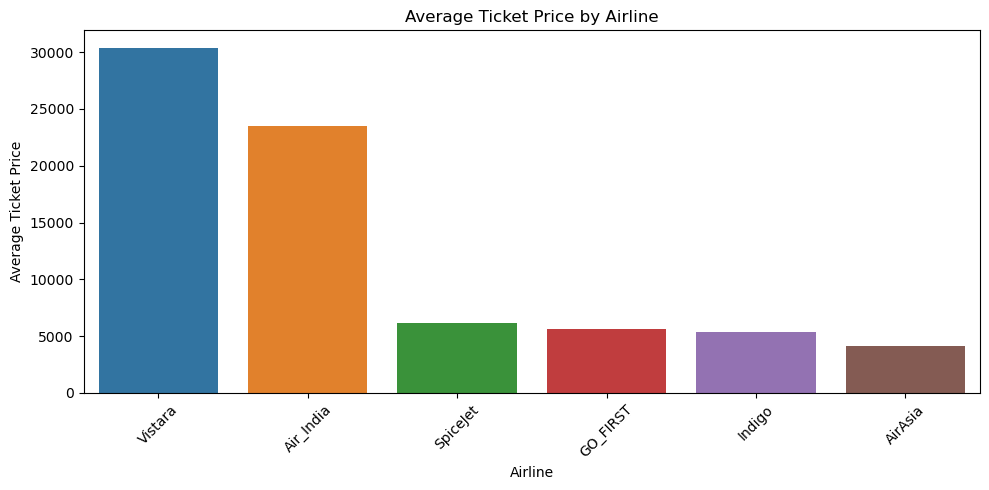

In [16]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=airline_prices.index,
    y=airline_prices.values
)

plt.title("Average Ticket Price by Airline")
plt.xlabel("Airline")
plt.ylabel("Average Ticket Price")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [17]:
class_prices = (
    df.groupby("class")["price"]
      .mean()
      .sort_values(ascending=False)
)

print(class_prices)

class
Business    52540.081124
Economy      6572.342383
Name: price, dtype: float64


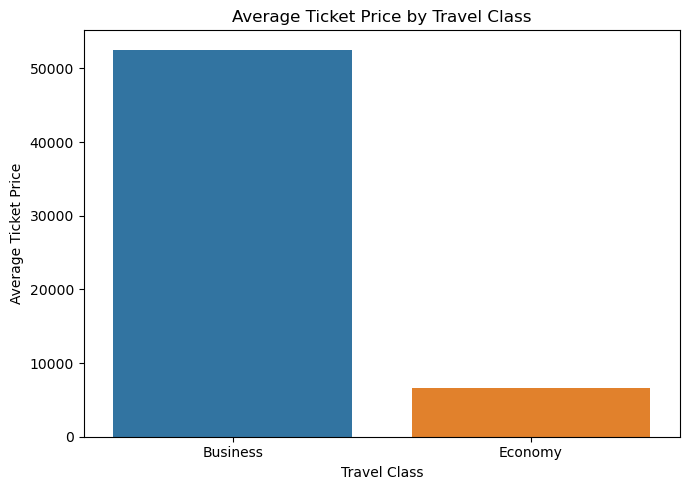

In [18]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=class_prices.index,
    y=class_prices.values
)

plt.title("Average Ticket Price by Travel Class")
plt.xlabel("Travel Class")
plt.ylabel("Average Ticket Price")

plt.tight_layout()
plt.show()

In [19]:
# Calculate average ticket price by number of stops

stops_prices = (
    df.groupby("stops")["price"]
      .mean()
      .sort_values(ascending=False)
)

print(stops_prices)

stops
one            22900.992482
two_or_more    14113.450775
zero            9375.938535
Name: price, dtype: float64


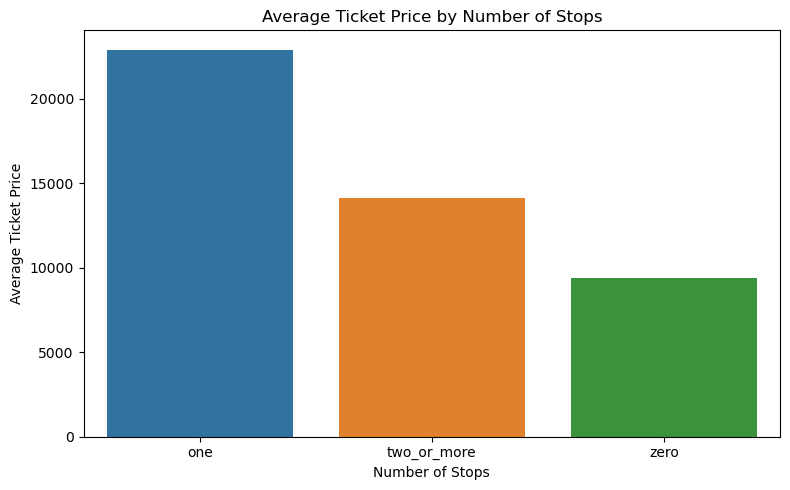

In [20]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=stops_prices.index,
    y=stops_prices.values
)

plt.title("Average Ticket Price by Number of Stops")
plt.xlabel("Number of Stops")
plt.ylabel("Average Ticket Price")

plt.tight_layout()
plt.show()

In [21]:
# Calculate average ticket price by route

route_prices = (
    df.groupby(["source_city", "destination_city"])["price"]
      .mean()
      .reset_index()
      .sort_values("price", ascending=False)
)

print(route_prices.head(10))

   source_city destination_city         price
5      Chennai        Bangalore  25081.850454
21     Kolkata          Chennai  23660.361040
3    Bangalore          Kolkata  23500.061229
0    Bangalore          Chennai  23321.850078
25      Mumbai        Bangalore  23147.873807
4    Bangalore           Mumbai  23128.618672
26      Mumbai          Chennai  22781.899112
9      Chennai           Mumbai  22765.849647
20     Kolkata        Bangalore  22744.808428
8      Chennai          Kolkata  22669.932407


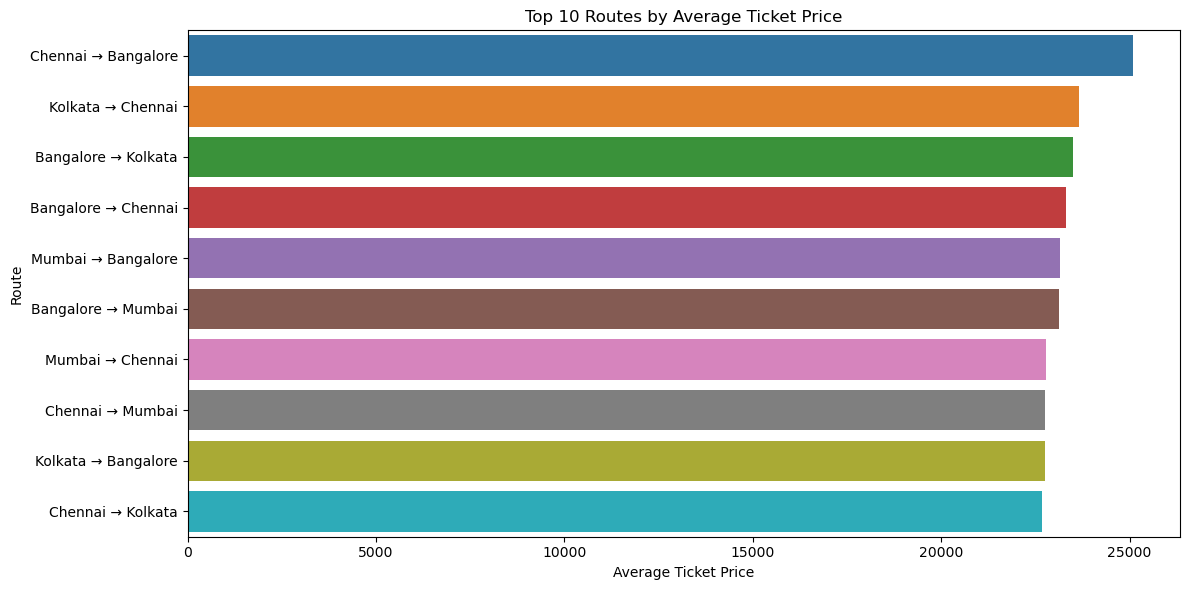

In [22]:
top_routes = route_prices.head(10).copy()

top_routes["route"] = (
    top_routes["source_city"]
    + " → "
    + top_routes["destination_city"]
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_routes,
    x="price",
    y="route"
)

plt.title("Top 10 Routes by Average Ticket Price")
plt.xlabel("Average Ticket Price")
plt.ylabel("Route")

plt.tight_layout()
plt.show()

In [23]:
# Average ticket price by airline and class

airline_class_prices = (
    df.groupby(["airline", "class"])["price"]
      .mean()
      .reset_index()
      .sort_values("price", ascending=False)
)

print(airline_class_prices)

     airline     class         price
6    Vistara  Business  55477.027777
1  Air_India  Business  47131.039212
7    Vistara   Economy   7806.943645
2  Air_India   Economy   7313.682169
5   SpiceJet   Economy   6179.278881
3   GO_FIRST   Economy   5652.007595
4     Indigo   Economy   5324.216303
0    AirAsia   Economy   4091.072742


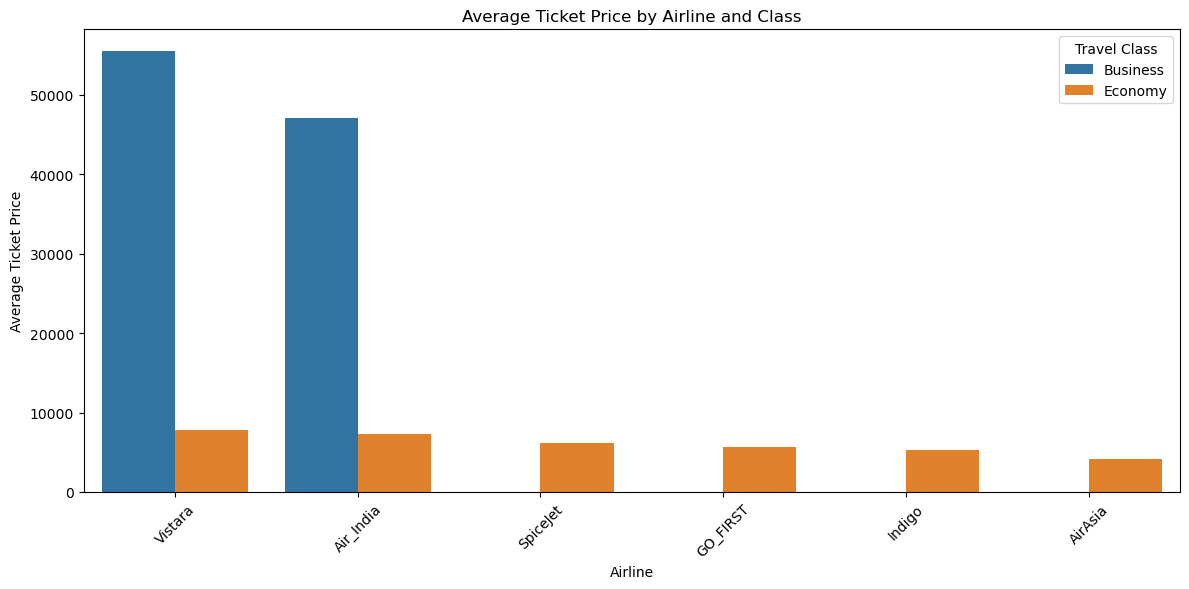

In [24]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=airline_class_prices,
    x="airline",
    y="price",
    hue="class"
)

plt.title("Average Ticket Price by Airline and Class")
plt.xlabel("Airline")
plt.ylabel("Average Ticket Price")
plt.xticks(rotation=45)
plt.legend(title="Travel Class")

plt.tight_layout()
plt.show()

In [25]:
class_counts = pd.crosstab(df["airline"], df["class"])

print(class_counts)

class      Business  Economy
airline                     
AirAsia           0    16098
Air_India     32898    47994
GO_FIRST          0    23173
Indigo            0    43120
SpiceJet          0     9011
Vistara       60589    67270


Text(0, 0.5, 'Average Ticket Pri')

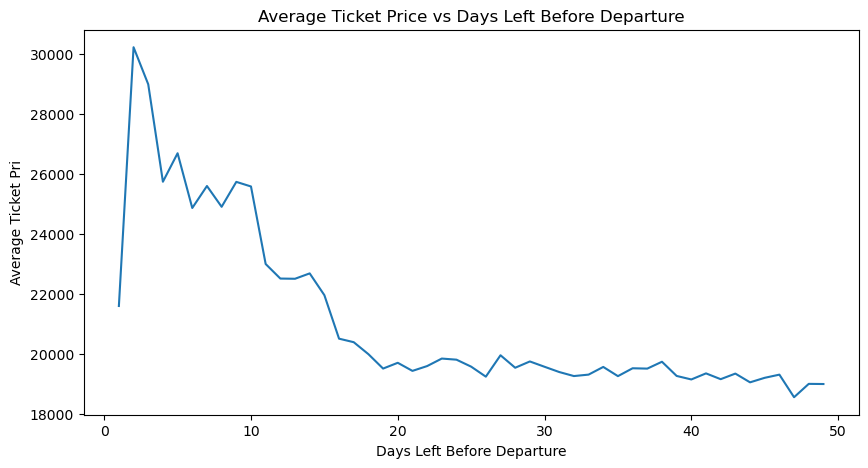

In [26]:
booking_prices = (
    df.groupby("days_left")["price"]
      .mean()
      .reset_index()
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=booking_prices,
    x="days_left",
    y="price"
)

plt.title("Average Ticket Price vs Days Left Before Departure")
plt.xlabel("Days Left Before Departure")
plt.ylabel("Average Ticket Pri")

Text(0.5, 0, 'Days Left')

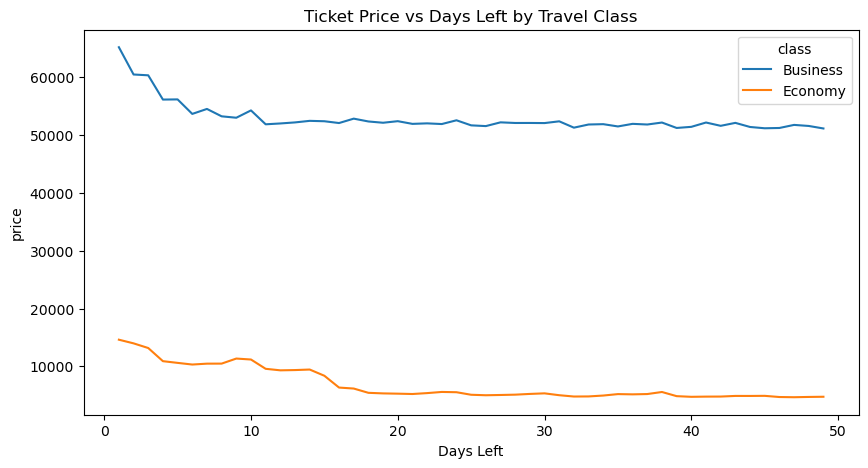

In [27]:
# Average ticket price by days left and travel class

booking_class = (
    df.groupby(["days_left", "class"])["price"]
      .mean()
      .reset_index()
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=booking_class,
    x="days_left",
    y="price",
    hue="class"
)

plt.title("Ticket Price vs Days Left by Travel Class")
plt.xlabel("Days Left")

In [28]:
# Create flight duration groups
df["duration_group"] = pd.cut(
    df["duration"],
    bins=[0, 5, 10, 15, 20, 30, 50],
    labels=[
        "0-5 hours",
        "5-10 hours",
        "10-15 hours",
        "15-20 hours",
        "20-30 hours",
        "30+ hours"
    ],
    include_lowest=True
)

In [29]:
duration_prices = (
    df.groupby("duration_group", observed=True)["price"]
      .mean()
      .reset_index()
)

print(duration_prices)

  duration_group         price
0      0-5 hours   9524.700547
1     5-10 hours  17771.231946
2    10-15 hours  24933.603765
3    15-20 hours  27373.403712
4    20-30 hours  25275.706258
5      30+ hours  17329.670710


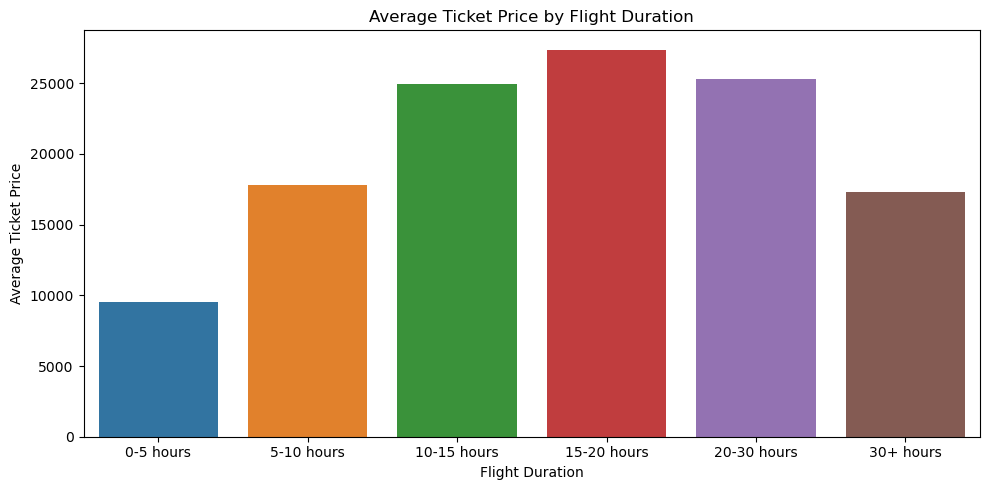

In [30]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=duration_prices,
    x="duration_group",
    y="price"
)

plt.title("Average Ticket Price by Flight Duration")
plt.xlabel("Flight Duration")
plt.ylabel("Average Ticket Price")

plt.tight_layout()
plt.show()

In [31]:
arrival_prices = (
    df.groupby("arrival_time")["price"]
      .mean()
      .sort_values(ascending=False)
)

print(arrival_prices)

arrival_time
Evening          23044.371615
Morning          22231.076098
Night            21586.758341
Afternoon        18494.598993
Early_Morning    14993.139521
Late_Night       11284.906078
Name: price, dtype: float64


In [32]:
df2=df.groupby(['flight','airline','class'],as_index=False).count()
df2['class'].value_counts()

Economy     1560
Business     295
Name: class, dtype: int64

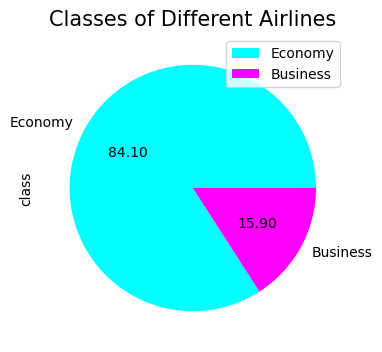

In [33]:
plt.figure(figsize=(6,4))
df2['class'].value_counts().plot(kind='pie',textprops={'color':'black'},autopct='%.2f',cmap='cool')
plt.title('Classes of Different Airlines',fontsize=15)
plt.legend(['Economy','Business'])
plt.show()

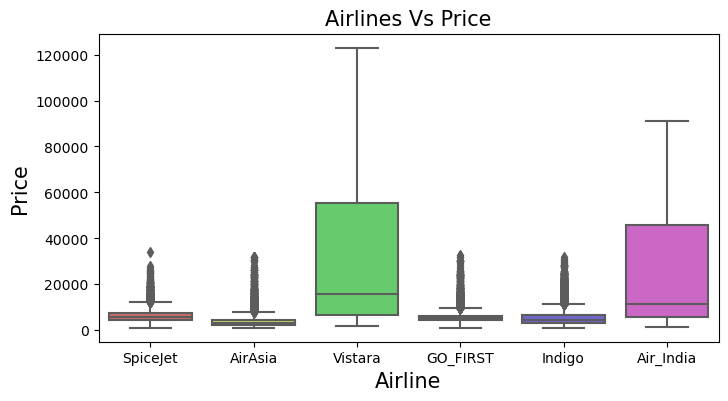

In [34]:

plt.figure(figsize=(8,4))
sns.boxplot(x=df['airline'],y=df['price'],palette='hls')
plt.title('Airlines Vs Price',fontsize=15)
plt.xlabel('Airline',fontsize=15)
plt.ylabel('Price',fontsize=15)
plt.show()
     

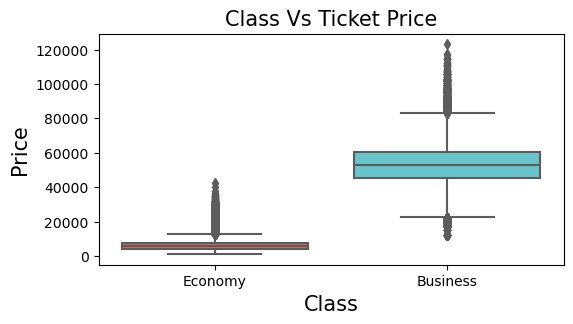

In [35]:
plt.figure(figsize=(6,3))
sns.boxplot(x='class',y='price',data=df,palette='hls')
plt.title('Class Vs Ticket Price',fontsize=15)
plt.xlabel('Class',fontsize=15)
plt.ylabel('Price',fontsize=15)
plt.show()

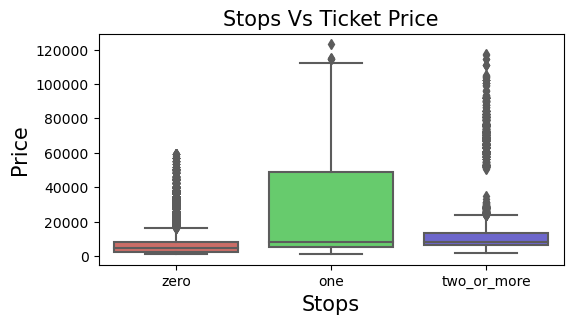

In [36]:
plt.figure(figsize=(6,3))
sns.boxplot(x='stops',y='price',data=df,palette='hls')
plt.title('Stops Vs Ticket Price',fontsize=15)
plt.xlabel('Stops',fontsize=15)
plt.ylabel('Price',fontsize=15)
plt.show()

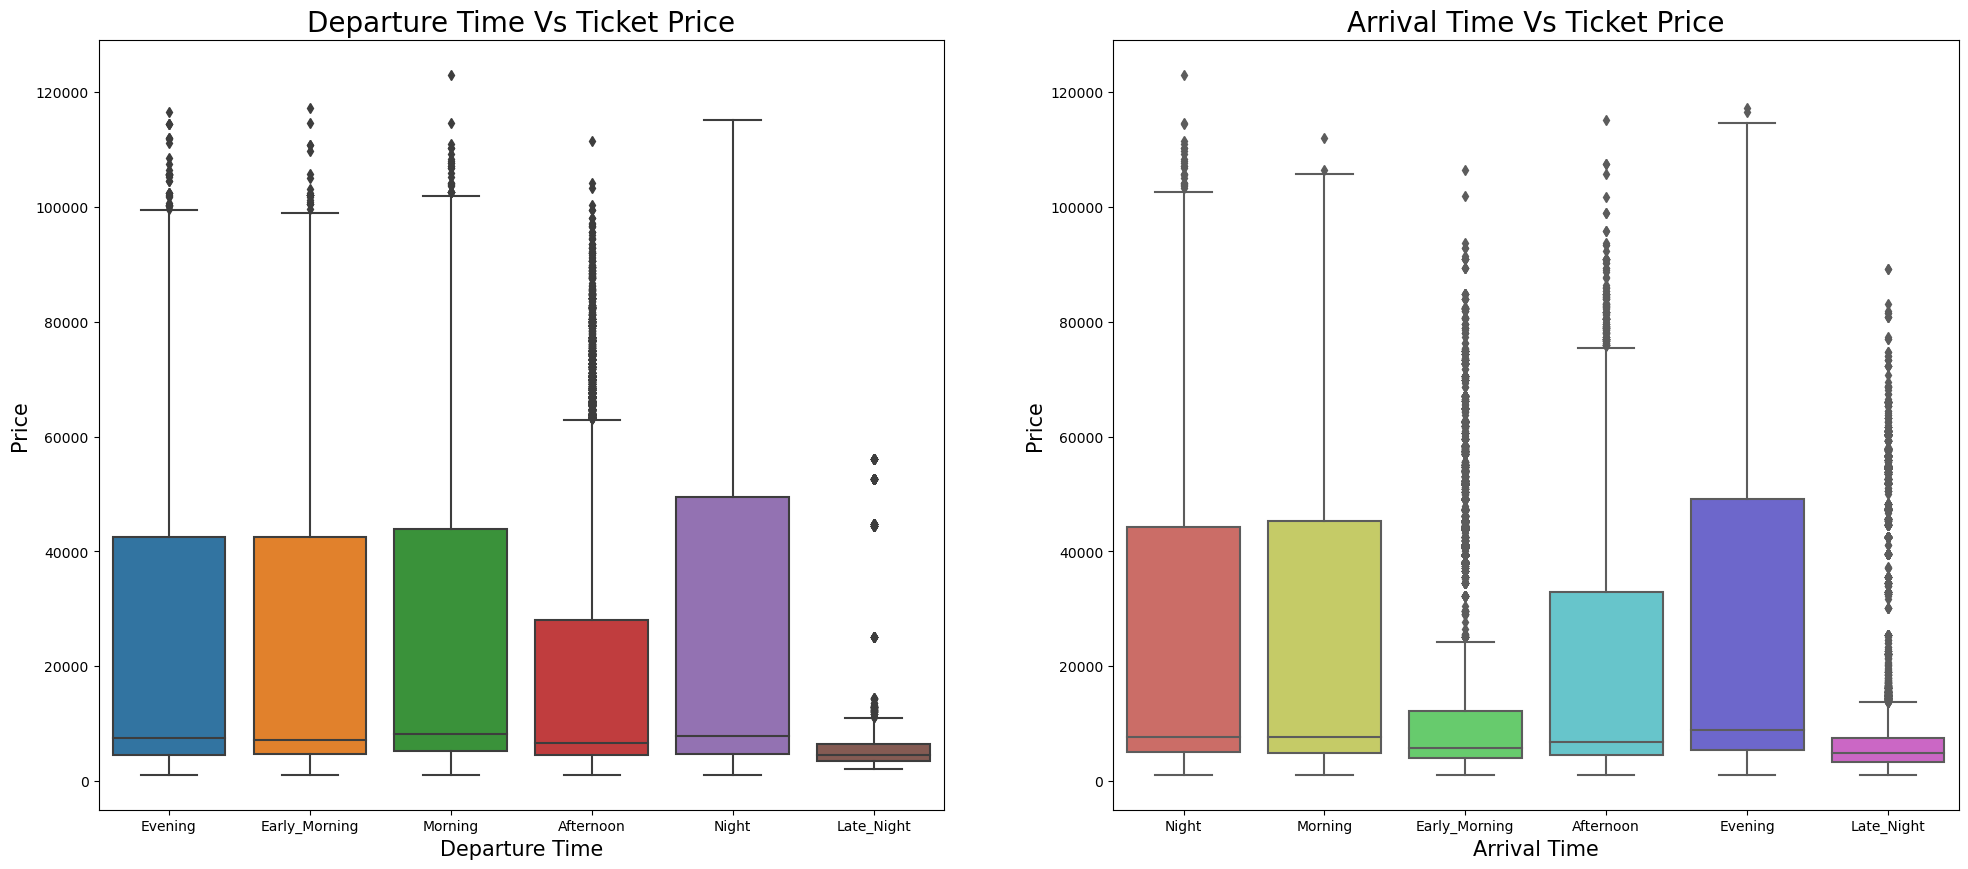

In [37]:
plt.figure(figsize=(24,10))
plt.subplot(1,2,1)
sns.boxplot(x='departure_time',y='price',data=df)
plt.title('Departure Time Vs Ticket Price',fontsize=20)
plt.xlabel('Departure Time',fontsize=15)
plt.ylabel('Price',fontsize=15)
plt.subplot(1,2,2)
sns.boxplot(x='arrival_time',y='price',data=df,palette='hls')
plt.title('Arrival Time Vs Ticket Price',fontsize=20)
plt.xlabel('Arrival Time',fontsize=15)
plt.ylabel('Price',fontsize=15)
plt.show()

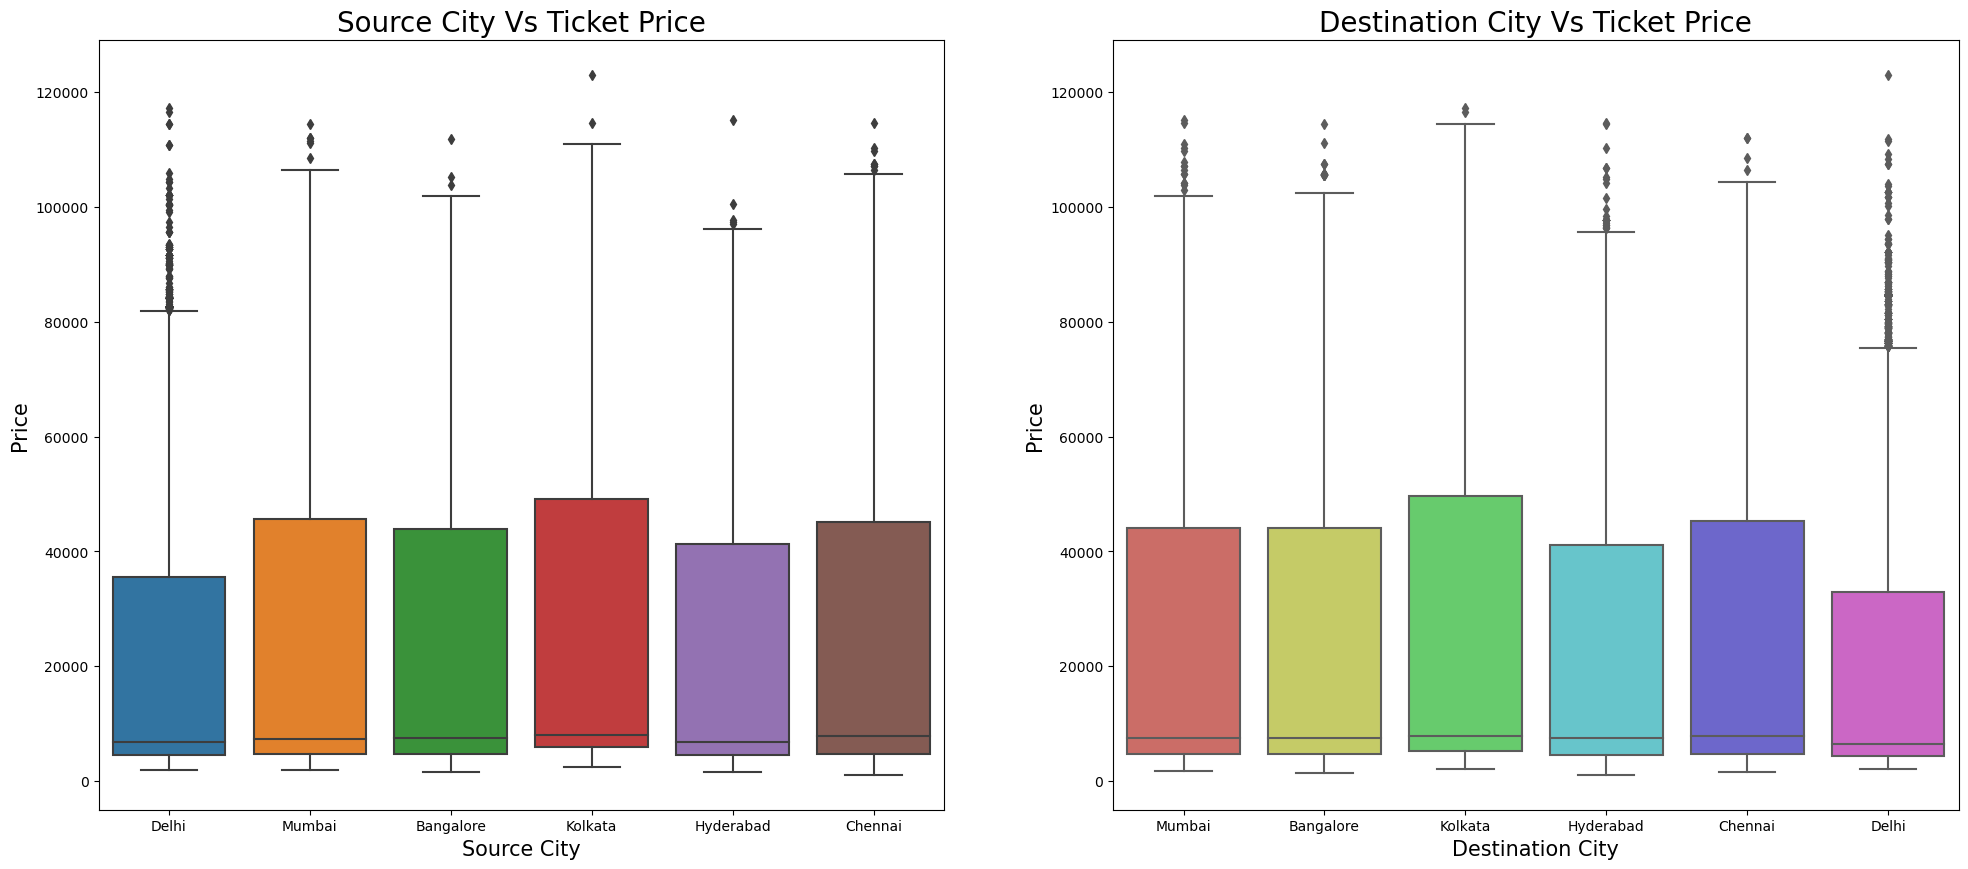

In [38]:
plt.figure(figsize=(24,10))
plt.subplot(1,2,1)
sns.boxplot(x='source_city',y='price',data=df)
plt.title('Source City Vs Ticket Price',fontsize=20)
plt.xlabel('Source City',fontsize=15)
plt.ylabel('Price',fontsize=15)
plt.subplot(1,2,2)
sns.boxplot(x='destination_city',y='price',data=df,palette='hls')
plt.title('Destination City Vs Ticket Price',fontsize=20)
plt.xlabel('Destination City',fontsize=15)
plt.ylabel('Price',fontsize=15)
plt.show()

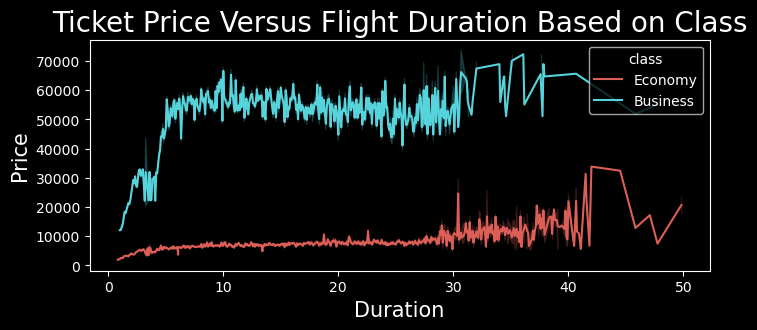

In [39]:
plt.style.use('dark_background')
plt.figure(figsize=(8,3))
sns.lineplot(data=df,x='duration',y='price',hue='class',palette='hls')
plt.title('Ticket Price Versus Flight Duration Based on Class',fontsize=20)
plt.xlabel('Duration',fontsize=15)
plt.ylabel('Price',fontsize=15)
plt.show()

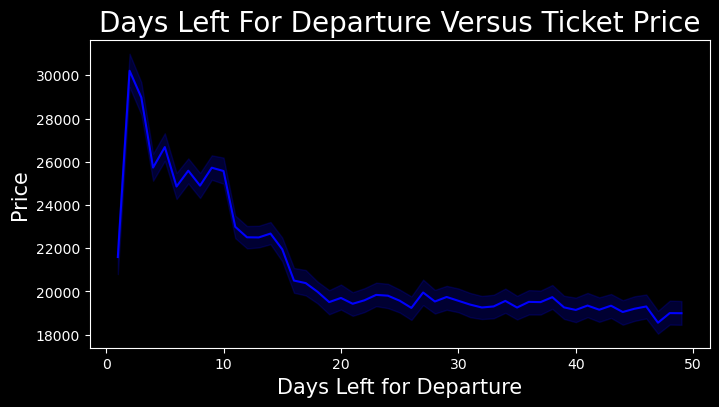

In [40]:
plt.figure(figsize=(8,4))
sns.lineplot(data=df,x='days_left',y='price',color='blue')
plt.title('Days Left For Departure Versus Ticket Price',fontsize=20)
plt.xlabel('Days Left for Departure',fontsize=15)
plt.ylabel('Price',fontsize=15)
plt.show()

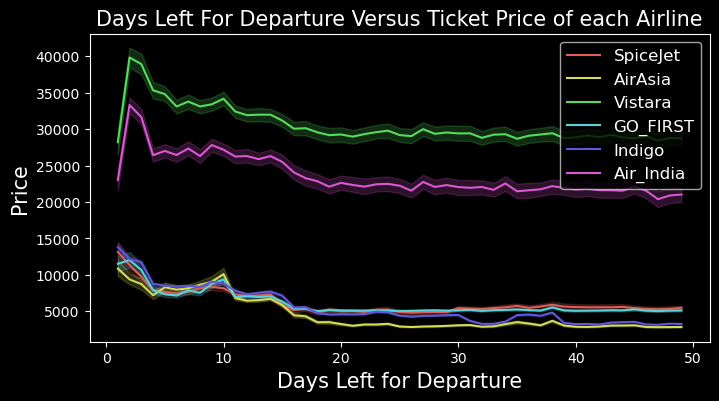

In [41]:
plt.figure(figsize=(8,4))
sns.lineplot(data=df,x='days_left',y='price',color='violet',hue='airline',palette='hls')
plt.title('Days Left For Departure Versus Ticket Price of each Airline',fontsize=15)
plt.legend(fontsize=12)
plt.xlabel('Days Left for Departure',fontsize=15)
plt.ylabel('Price',fontsize=15)
plt.show()

In [42]:
df.groupby(['flight','source_city','destination_city','airline',
            'class'],as_index=False).count().groupby(['source_city','destination_city'],as_index=False)['flight'].count().head(10)
     

,source_city,destination_city,flight
0,Bangalore,Chennai,106
1,Bangalore,Delhi,227
2,Bangalore,Hyderabad,132
3,Bangalore,Kolkata,171
4,Bangalore,Mumbai,175
5,Chennai,Bangalore,69
6,Chennai,Delhi,105
7,Chennai,Hyderabad,82
8,Chennai,Kolkata,110
9,Chennai,Mumbai,94


In [43]:
df.groupby(['airline','source_city','destination_city'],as_index=False)['price'].mean().head(10)


,airline,source_city,destination_city,price
0,AirAsia,Bangalore,Chennai,2073.043478
1,AirAsia,Bangalore,Delhi,4807.092426
2,AirAsia,Bangalore,Hyderabad,2931.494792
3,AirAsia,Bangalore,Kolkata,4443.468160
4,AirAsia,Bangalore,Mumbai,3342.385350
5,AirAsia,Chennai,Bangalore,1914.760870
6,AirAsia,Chennai,Delhi,3697.314003
7,AirAsia,Chennai,Hyderabad,2053.182540
8,AirAsia,Chennai,Kolkata,3682.338762
9,AirAsia,Chennai,Mumbai,2691.100000


In [44]:
import sys
print(sys.executable)
print(sys.version)

C:\Users\sanje\anaconda3\python.exe
3.11.4 | packaged by Anaconda, Inc. | (main, Jul  5 2023, 13:38:37) [MSC v.1916 64 bit (AMD64)]


In [45]:
import mysql.connector
print(mysql.connector.__version__)

9.5.0


In [46]:
import sys
print(sys.executable)

import mysql.connector
print(mysql.connector.__version__)

C:\Users\sanje\anaconda3\python.exe
9.5.0


In [47]:
import mysql.connector
print(mysql.connector.__version__)

9.5.0


In [48]:
import sys
print(sys.executable)

C:\Users\sanje\anaconda3\python.exe


In [49]:
import mysql.connector
print("Import successful")

Import successful


In [ ]:
import mysql.connector

mydb = mysql.connector.connect(
    host="127.0.0.1",
    port=3306,
    user="root",
    password="1234",
    connection_timeout=5
)

print("Connected:", mydb.is_connected())


In [ ]:
import mysql.connector
print("Import successful")

In [ ]:
mydb = mysql.connector.connect(
    host="127.0.0.1",
    user="root",
    password="1234",
    connection_timeout=5,
    use_pure=True
)

print("Connected:", mydb.is_connected())

In [ ]:
cursor = mydb.cursor()

cursor.execute("CREATE DATABASE IF NOT EXISTS airline_analysis")
cursor.execute("USE airline_analysis")

print("Database created and selected successfully!")

In [ ]:
create_table = """
CREATE TABLE IF NOT EXISTS airline_data (
    airline VARCHAR(50),
    flight VARCHAR(50),
    source_city VARCHAR(50),
    departure_time VARCHAR(50),
    stops VARCHAR(50),
    arrival_time VARCHAR(50),
    destination_city VARCHAR(50),
    travel_class VARCHAR(50),
    duration FLOAT,
    days_left INT,
    price INT
)
"""

cursor.execute(create_table)
mydb.commit()

print("Airline table created successfully!")

In [ ]:
sql_df = df[
    [
        "airline",
        "flight",
        "source_city",
        "departure_time",
        "stops",
        "arrival_time",
        "destination_city",
        "class",
        "duration",
        "days_left",
        "price"
    ]
].copy()

sql_df.rename(columns={"class": "travel_class"}, inplace=True)

print(sql_df.shape)